**02 - Embeddings + Chroma (Parts B and C)**

Goal: turn every fact check claim into numbers that capture its meaning(embeddings) and store them in Chroma, so a forward in hindi or english can find the matching fact check even if no words are common

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

**Piece 1** - what is an embedding(tiny demo before using real data)

In [2]:
from langchain_huggingface import HuggingFaceEmbeddings

In [3]:
#multilingual model(50+ languages incl hindi),runs on my laptop,first run downloads it(~470MB)
MODEL_NAME="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
embeddings=HuggingFaceEmbeddings(model_name=MODEL_NAME)

W1107 01:20:39.527000 42769 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6834.25it/s]

In [4]:
#0,1,2 mean the same thing in english,hindi and hinglish
#3,4 are a different rumour(english + hindi)
sentences=[
    "Rs 2000 notes will be banned from tomorrow",
    "कल से 2000 के नोट बंद हो जाएंगे",
    "Kal se 2000 ke note band ho jayenge",
    "Drinking hot water cures coronavirus",
    "गरम पानी पीने से कोरोना ठीक हो जाता है"
]

In [5]:
vectors=embeddings.embed_documents(sentences)

In [6]:
#each sentence became a list of numbers
len(vectors),len(vectors[0])

(5, 384)

In [7]:
#first 10 numbers of the first sentence(on their own they mean nothing,only comparing them matters)
np.round(vectors[0][:10],3)

array([-0.085, -0.103, -0.074,  0.139,  0.346,  0.047, -0.193,  0.155,
       -0.116,  0.323])

In [8]:
#cosine similarity:how much 2 vectors point in the same direction(1=same meaning,0=unrelated)
#same as the dot product and np.linalg.norm from my numpy practice
def cosine_similarity(a,b):
  return np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b))

In [9]:
cosine_similarity(vectors[0],vectors[1])

np.float64(0.5060319294347622)

In [10]:
cosine_similarity(vectors[0],vectors[3])

np.float64(0.06847312850653144)

In [11]:
#comparing every sentence with every other sentence
n=len(sentences)
sim_matrix=np.zeros((n,n))
for i in range(n):
  for j in range(n):
    sim_matrix[i][j]=cosine_similarity(vectors[i],vectors[j])

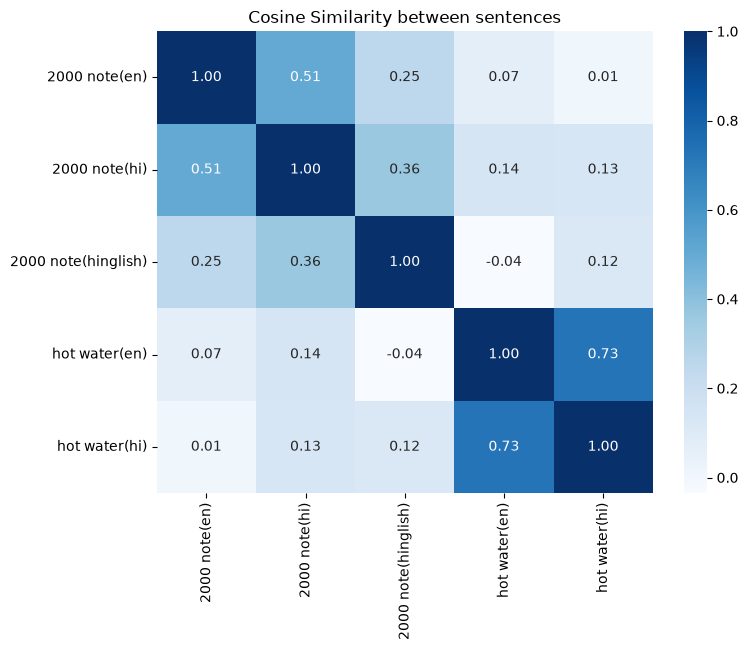

In [12]:
labels=["2000 note(en)","2000 note(hi)","2000 note(hinglish)","hot water(en)","hot water(hi)"]
plt.figure(figsize=(8,6))
sns.heatmap(sim_matrix,annot=True,fmt=".2f",cmap="Blues",xticklabels=labels,yticklabels=labels)
plt.title("Cosine Similarity between sentences")
plt.show()

**Observations** (your turn:what do you notice in the heatmap?)

1.

---

2.

**Piece 1b** - comparing 4 free embedding models that run on my laptop(english,hindi and hinglish)

In [13]:
#hinglish was weak above(0.25),most whatsapp forwards are hinglish so testing 4 free models before embedding 16,953 claims
#4 rumours x 3 versions(english,hindi,hinglish) = 12 sentences
sentences=[
    "Rs 2000 notes will be banned from tomorrow",
    "कल से 2000 के नोट बंद हो जाएंगे",
    "Kal se 2000 ke note band ho jayenge",
    "Drinking hot water cures coronavirus",
    "गरम पानी पीने से कोरोना ठीक हो जाता है",
    "Garam pani peene se corona theek ho jata hai",
    "Government is giving free laptops to all students, register on this link",
    "सरकार सभी छात्रों को मुफ्त लैपटॉप दे रही है, इस लिंक पर रजिस्टर करें",
    "Sarkar sabhi students ko free laptop de rahi hai, is link par register karo",
    "WhatsApp will start charging money for messages from next month",
    "अगले महीने से व्हाट्सएप मैसेज भेजने के पैसे लेगा",
    "Agle mahine se WhatsApp message bhejne ke paise lega"
]
labels=["2000(en)","2000(hi)","2000(hinglish)",
        "water(en)","water(hi)","water(hinglish)",
        "laptop(en)","laptop(hi)","laptop(hinglish)",
        "whatsapp(en)","whatsapp(hi)","whatsapp(hinglish)"]

In [14]:
#all 4 are free and run on my laptop(no api key,no limits)
#e5 models were trained with a "query: " prefix in front of the text,without it they work worse
models={
    "MiniLM":{"name":"sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2","prefix":""},
    "e5-small":{"name":"intfloat/multilingual-e5-small","prefix":"query: "},
    "bge-m3":{"name":"BAAI/bge-m3","prefix":""},
    "qwen3":{"name":"Qwen/Qwen3-Embedding-0.6B","prefix":""}
}

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 14106.72it/s]

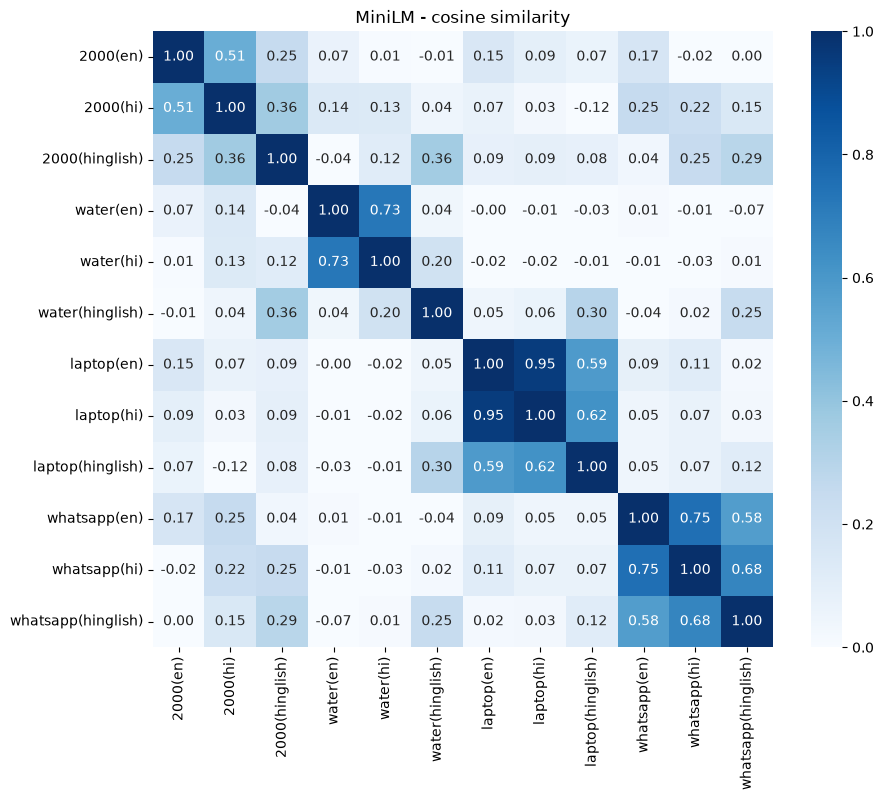

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6354.81it/s]

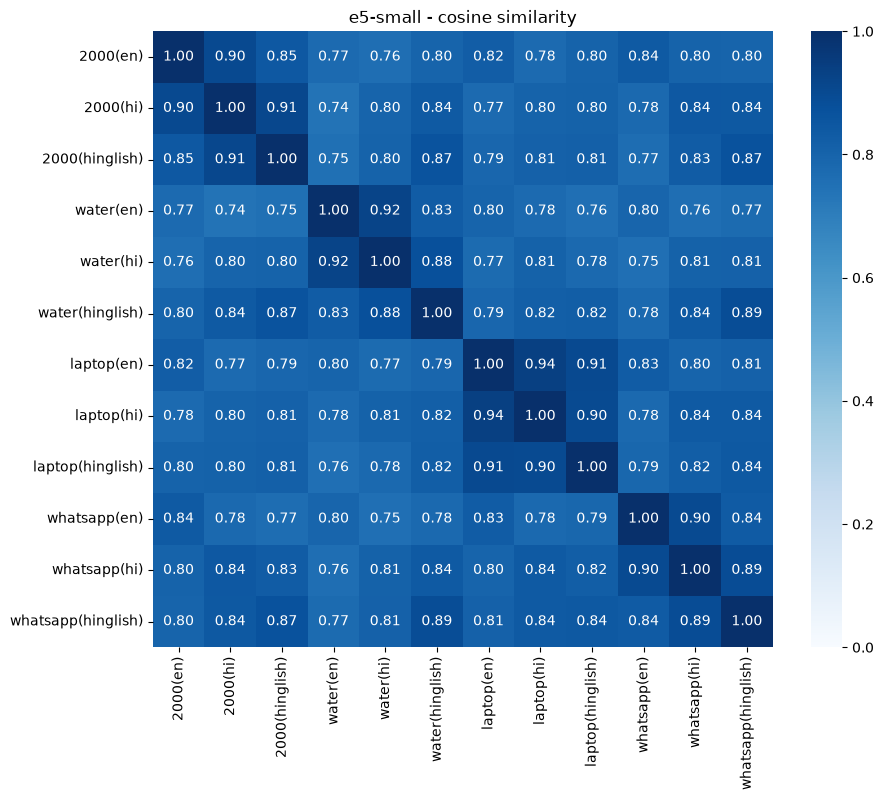

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 37788.26it/s]

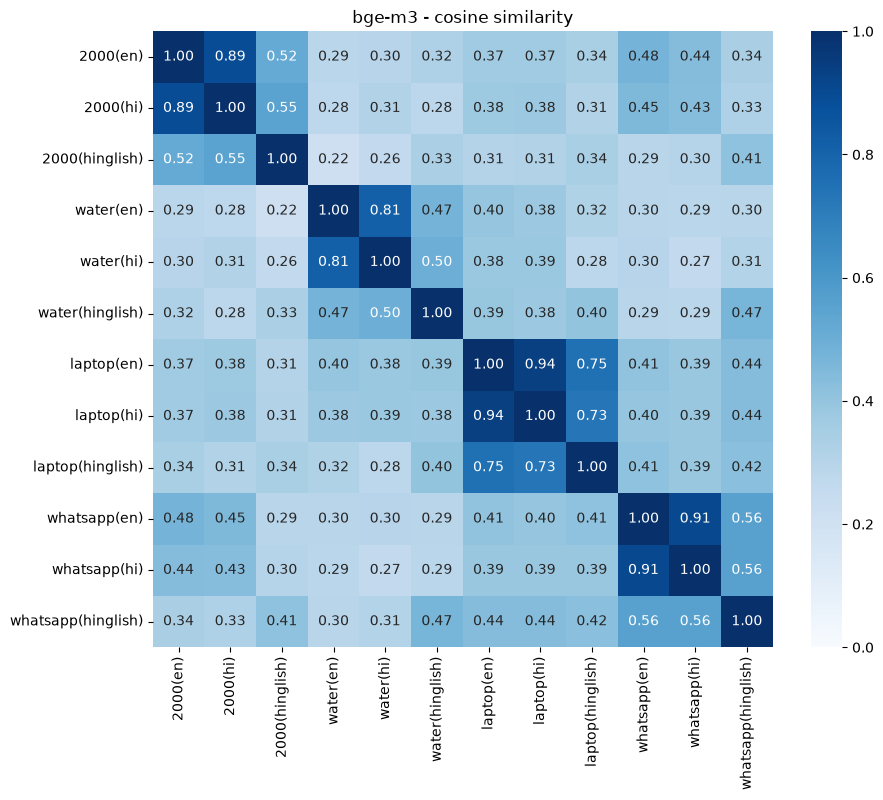

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 5145.98it/s]

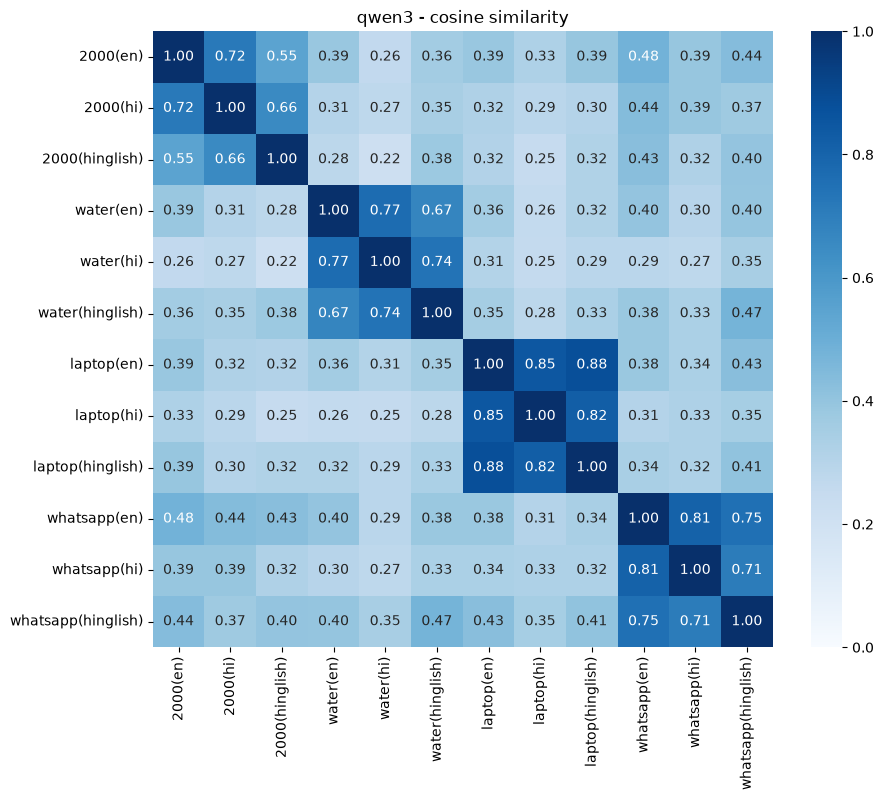

In [15]:
#same heatmap as piece 1,one per model
#good model = 4 dark blocks on the diagonal(same rumour in 3 languages) and light everywhere else(different rumours)
for model_name,m in models.items():
  emb=HuggingFaceEmbeddings(model_name=m["name"])
  vectors=emb.embed_documents([m["prefix"]+s for s in sentences])

  n=len(sentences)
  sim_matrix=np.zeros((n,n))
  for i in range(n):
    for j in range(n):
      sim_matrix[i][j]=cosine_similarity(vectors[i],vectors[j])

  plt.figure(figsize=(10,8))
  sns.heatmap(sim_matrix,annot=True,fmt=".2f",cmap="Blues",xticklabels=labels,yticklabels=labels,vmin=0,vmax=1)
  plt.title(f"{model_name} - cosine similarity")
  plt.show()

**Observations** (your turn:which model has the clearest 4 blocks? look at the hinglish rows)

1.

---

2.

**Piece 1c** - speed check(how long would all 16,953 claims take on my laptop?)

In [16]:
import sqlite3
import time
conn=sqlite3.connect("../data/factchecks.db")
sample=pd.read_sql("SELECT claim FROM factchecks LIMIT 200",conn)["claim"].tolist()
conn.close()
len(sample)

200

In [17]:
#timing 200 real claims and scaling it up to 16,953(mps = my mac's graphics chip)
speed=[]
for model_name in ["MiniLM","bge-m3","qwen3"]:
  emb=HuggingFaceEmbeddings(model_name=models[model_name]["name"])
  emb.embed_documents(sample[:5])#warm up(first call is always slower)
  start=time.time()
  emb.embed_documents(sample)
  seconds=time.time()-start
  speed.append({"model":model_name,"200 claims (s)":round(seconds,1),"all 16,953 (min)":round(seconds/200*16953/60,1)})
pd.DataFrame(speed)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6063.38it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 29817.69it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 5290.17it/s]

,model,200 claims (s),"all 16,953 (min)"
0,MiniLM,0.7,0.9
1,bge-m3,2.0,2.8
2,qwen3,4.5,6.4


**Which model?** (your decision,write the reason here and in DECISIONS.md)

-